# Hospital Patient Flow and Resource Allocation: Data Cleaning and EDA
This notebook validates, cleans, transforms, and explores the [Hospital Operations Dataset](https://www.kaggle.com/datasets/arsalanjamal002/hospital-operations-dataset) to prepare clean tables for decision modeling and Power BI visualization.


### 1. Import Required Libraries
Load pandas, numpy, matplotlib, and seaborn for data manipulation and exploratory data analysis.

openpyxl is used to write and export datasets into Microsoft Excel (`.xlsx`) format.


In [2]:
%pip install pandas numpy matplotlib seaborn openpyxl


   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 883.0 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/10.9 MB 993.8 kB/s eta 0:00:11
   ---- ----------------------------------- 1.3/10.9 MB 1.2 MB/s eta 0:00:09
   ----- ---------------------------------- 1.6/10.9 MB 1.1 MB/s eta 0:00:09
   ----- ---------------------------------- 1.6/10.9 MB 1.1 MB/s eta 0:00:09
   ------ --------------------------------- 1.8/10.9 MB 1.1 MB/s eta 0:00:09
   ------- -------------------------------- 2.1/10.9 MB 1.1 MB/s eta 0:00:08
   -------- ------------------------------- 2.4/10.9 MB 1.1 MB/s eta 0:00:08
   --------- ------------------------------ 2.6/10.9 MB 1.1 MB/s eta 0:00:08
   ---------- ----------------------------- 2.9/10.9 MB 1.1 MB/s eta 0:00:08
   ----------- -

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


Matplotlib is building the font cache; this may take a moment.


### 2. Load Dataset
Load the file and inspect the first ten records.


In [11]:
# load the dataset
df = pd.read_csv("Hospital_Operations_Dataset.csv")
df.head(11)


,Patient_ID,Age,Gender,Department,Diagnosis,Severity_Level,Admission_Date,Discharge_Date,Length_of_Stay_Days,Wait_Time_Minutes,Doctor_ID,Insurance_Type,Treatment_Cost_USD,Readmission_Flag,Outcome
0,PAT000001,23,Male,Gynecology,Cancer,Low,2026-05-02 06:06:47.667330,2026-05-04 06:06:47.667330,2,79,DOC0350,Employer,485,0,Recovered
1,PAT000002,48,Male,Neurology,Kidney Disease,Medium,2026-03-24 15:52:16.633920,2026-03-30 15:52:16.633920,6,167,DOC0267,Private,3487,0,Improved
2,PAT000003,63,Male,Neurology,Stroke,Low,2025-09-07 03:51:37.073134,2025-09-10 03:51:37.073134,3,281,DOC0197,Self-Pay,716,0,Recovered
3,PAT000004,85,Male,Emergency,Asthma,Medium,2024-11-19 00:17:09.630895,2024-11-21 00:17:09.630895,2,271,DOC0009,Government,2111,0,Recovered
4,PAT000005,93,Female,Neurology,Pneumonia,Medium,2024-07-20 04:48:22.195440,2024-07-27 04:48:22.195440,7,112,DOC0219,Self-Pay,4968,0,Transferred
5,PAT000006,83,Male,Emergency,Diabetes,Low,2026-06-04 06:21:26.664628,2026-06-05 06:21:26.664628,1,262,DOC0499,Self-Pay,862,0,Transferred
6,PAT000007,66,Male,Oncology,Stroke,Low,2025-10-01 14:02:20.314286,2025-10-04 14:02:20.314286,3,145,DOC0255,Government,651,0,Recovered
7,PAT000008,20,Female,General Surgery,Heart Disease,Low,2026-06-19 23:16:56.484386,2026-06-22 23:16:56.484386,3,204,DOC0038,Self-Pay,867,0,Recovered
8,PAT000009,85,Female,Dermatology,Cancer,High,2024-07-01 02:04:52.368696,2024-07-16 02:04:52.368696,15,51,DOC0244,Private,14861,0,Recovered
9,PAT000010,52,Female,Pediatrics,Fracture,Low,2025-08-02 21:40:09.073370,2025-08-05 21:40:09.073370,3,127,DOC0318,Government,939,0,Improved


### 3. Inspect Dataset Dimensions and Data Types
Next is to verify the exact row count, column count, non-null totals, and data types across all 15 variables.


In [7]:
# check total number of rows and columns
print(df.shape)

# check exact column names, non-null counts, and data types
df.info()


(100000, 15)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   Patient_ID           100000 non-null  str  
 1   Age                  100000 non-null  int64
 2   Gender               100000 non-null  str  
 3   Department           100000 non-null  str  
 4   Diagnosis            100000 non-null  str  
 5   Severity_Level       100000 non-null  str  
 6   Admission_Date       100000 non-null  str  
 7   Discharge_Date       100000 non-null  str  
 8   Length_of_Stay_Days  100000 non-null  int64
 9   Wait_Time_Minutes    100000 non-null  int64
 10  Doctor_ID            100000 non-null  str  
 11  Insurance_Type       100000 non-null  str  
 12  Treatment_Cost_USD   100000 non-null  int64
 13  Readmission_Flag     100000 non-null  int64
 14  Outcome              100000 non-null  str  
dtypes: int64(5), str(10)
memory usage: 11.4 MB


### 4. Validate Primary Key Uniqueness and Duplicates
Checking for completely duplicated records and confirm that every `Patient_ID` represents a unique patient visit.

In [9]:
# check for  duplicated rows
print("duplicate rows:", df.duplicated().sum())

# check if every patient_id is unique
print("unique patient ids:", df["Patient_ID"].nunique())


duplicate rows: 0
unique patient ids: 100000


### 5. Audit Categorical Values and Numeric Distributions
Confirm the allowed category values (`Severity_Level`, `Outcome`, `Readmission_Flag`, `Department`) and inspect numeric ranges (`Age`, `Length_of_Stay_Days`, `Wait_Time_Minutes`, `Treatment_Cost_USD`) for outliers.


In [12]:
# check unique values in categorical columns
print("severity levels:", df["Severity_Level"].unique())
print("outcomes:", df["Outcome"].unique())
print("readmission flags:", df["Readmission_Flag"].unique())
print("departments:", df["Department"].unique())

# check minimum and maximum values for numeric columns
df[["Age", "Length_of_Stay_Days", "Wait_Time_Minutes", "Treatment_Cost_USD"]].describe()


severity levels: <StringArray>
['Low', 'Medium', 'High', 'Critical']
Length: 4, dtype: str
outcomes: <StringArray>
['Recovered', 'Improved', 'Transferred', 'Deceased']
Length: 4, dtype: str
readmission flags: [0 1]
departments: <StringArray>
[     'Gynecology',       'Neurology',       'Emergency',        'Oncology',
 'General Surgery',     'Dermatology',      'Pediatrics',     'Orthopedics',
             'ICU',      'Cardiology']
Length: 10, dtype: str


,Age,Length_of_Stay_Days,Wait_Time_Minutes,Treatment_Cost_USD
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,47.426220,5.357330,152.036470,4893.894900
std,27.729468,4.966795,85.560948,7710.109305
min,0.000000,1.000000,5.000000,100.000000
25%,23.000000,2.000000,78.000000,662.000000
50%,47.000000,3.000000,152.000000,2142.000000
75%,71.000000,7.000000,226.000000,5002.250000
max,95.000000,30.000000,300.000000,49999.000000


### 6. Convert Date Columns and Validate Chronological Sequence
Convert `Admission_Date` and `Discharge_Date` from text strings to datetime objects, and also making sure that no discharge occurs prior to admission, and inspect clinical outcome counts.


In [13]:
# convert admission and discharge columns from text to datetime
df["Admission_Date"] = pd.to_datetime(df["Admission_Date"])
df["Discharge_Date"] = pd.to_datetime(df["Discharge_Date"])

# check if any discharge date is earlier than admission date
invalid_dates = df[df["Discharge_Date"] < df["Admission_Date"]]
print("invalid date rows:", len(invalid_dates))

# check count of each outcome category
print(df["Outcome"].value_counts())


invalid date rows: 0
Outcome
Recovered      68568
Improved       20602
Transferred     8397
Deceased        2433
Name: count, dtype: int64


### 7. Create New Columns and Clean Headers
Derive operational flow columns (`arrival_day`, `arrival_month`, `wait_category`), remove non-operational columns (`Gender`, `Diagnosis`, `Insurance_Type`), and rename retained fields into clean lowercase headers.


In [14]:
# create derived time columns for arrival analysis
df["arrival_day"] = df["Admission_Date"].dt.day_name()
df["arrival_month"] = df["Admission_Date"].dt.to_period("M").astype(str)

# categorize wait times into operational delay tiers
df["wait_category"] = pd.cut(
    df["Wait_Time_Minutes"],
    bins=[-1, 30, 60, 1000],
    labels=["normal", "delayed", "critical"]
)

# select only relevant columns and rename to clean lowercase headers
clean_cols = {
    "Patient_ID": "patient_id",
    "Age": "age",
    "Department": "department",
    "Severity_Level": "severity",
    "Admission_Date": "admission_date",
    "Discharge_Date": "discharge_date",
    "arrival_day": "arrival_day",
    "arrival_month": "arrival_month",
    "Length_of_Stay_Days": "bed_stay_days",
    "Wait_Time_Minutes": "wait_time_mins",
    "wait_category": "wait_category",
    "Doctor_ID": "doctor_id",
    "Treatment_Cost_USD": "cost_usd",
    "Readmission_Flag": "readmission",
    "Outcome": "outcome"
}

df_clean = df[list(clean_cols.keys())].rename(columns=clean_cols)

# check the final cleaned shape and first 5 rows
print("cleaned shape:", df_clean.shape)
df_clean.head()


cleaned shape: (100000, 15)


,patient_id,age,department,severity,admission_date,discharge_date,arrival_day,arrival_month,bed_stay_days,wait_time_mins,wait_category,doctor_id,cost_usd,readmission,outcome
0,PAT000001,23,Gynecology,Low,2026-05-02 06:06:47.667330,2026-05-04 06:06:47.667330,Saturday,2026-05,2,79,critical,DOC0350,485,0,Recovered
1,PAT000002,48,Neurology,Medium,2026-03-24 15:52:16.633920,2026-03-30 15:52:16.633920,Tuesday,2026-03,6,167,critical,DOC0267,3487,0,Improved
2,PAT000003,63,Neurology,Low,2025-09-07 03:51:37.073134,2025-09-10 03:51:37.073134,Sunday,2025-09,3,281,critical,DOC0197,716,0,Recovered
3,PAT000004,85,Emergency,Medium,2024-11-19 00:17:09.630895,2024-11-21 00:17:09.630895,Tuesday,2024-11,2,271,critical,DOC0009,2111,0,Recovered
4,PAT000005,93,Neurology,Medium,2024-07-20 04:48:22.195440,2024-07-27 04:48:22.195440,Saturday,2024-07,7,112,critical,DOC0219,4968,0,Transferred


### 8. Export Cleaned Dataset
Saving the final dataset as both CSV and Excel files for Power BI dashboards and Excel decision modeling.


In [15]:
# save cleaned dataset as csv for power bi and github
df_clean.to_csv("cleaned_hospital_data.csv", index=False)

# save cleaned dataset as excel workbook
df_clean.to_excel("cleaned_hospital_data.xlsx", index=False)

print("the files have been saved ")


the files have been saved 


### 9. Exploratory Data Analysis: Overall Hospital KPIs
This involves calculating the key performance metrics across all 100,000 cleaned patient records, including total arrivals, average wait times, bed occupancy days, active doctors, and readmission rates.


In [18]:
# calculate facility-wide metrics
total_arrivals = len(df_clean)
avg_wait = round(df_clean["wait_time_mins"].mean(), 2)
median_wait = round(df_clean["wait_time_mins"].median(), 2)
avg_los = round(df_clean["bed_stay_days"].mean(), 2)
total_bed_days = df_clean["bed_stay_days"].sum()
unique_doctors = df_clean["doctor_id"].nunique()
readmission_rate = round(df_clean["readmission"].mean() * 100, 2)

# print overall hospital kpis
print("total arrivals:", total_arrivals)
print("average wait time (mins):", avg_wait)
print("median wait time (mins):", median_wait)
print("average length of stay (days):", avg_los)
print("total bed days occupied:", total_bed_days)
print("unique active doctors:", unique_doctors)
print("readmission rate (%):", readmission_rate)


total arrivals: 100000
average wait time (mins): 152.04
median wait time (mins): 152.0
average length of stay (days): 5.36
total bed days occupied: 535733
unique active doctors: 500
readmission rate (%): 7.48


### 10. Departmental Demand, Wait Times, and Doctor Workload
Group the cleaned data by hospital department to compare patient arrival volumes, average waiting times, total bed days occupied, active doctor counts, and patient-to-doctor workload ratios.


In [22]:
# group data by department to calculate operational metrics
dept_table = df_clean.groupby("department").agg(
    arrivals=("patient_id", "count"),
    avg_wait=("wait_time_mins", "mean"),
    total_bed_days=("bed_stay_days", "sum"),
    avg_los=("bed_stay_days", "mean"),
    doctors=("doctor_id", "nunique"),
    avg_cost=("cost_usd", "mean")
).round(2)

# calculate average number of patients handled per doctor in each department
dept_table["patients_per_doctor"] = (dept_table["arrivals"] / dept_table["doctors"]).round(1)

# sort departments from highest average wait time to lowest
dept_table = dept_table.sort_values(by="avg_wait", ascending=False)

# calculate average number of patients handled per doctor as a whole number
dept_table["patients_per_doctor"] = (dept_table["arrivals"] / dept_table["doctors"]).round(0).astype(int)

# display the departmental summary table
dept_table


,arrivals,avg_wait,total_bed_days,avg_los,doctors,avg_cost,patients_per_doctor
department,,,,,,,
ICU,9987,152.95,54041,5.41,500,4994.06,20
Neurology,10049,152.70,53142,5.29,500,4786.23,20
General Surgery,9889,152.63,53517,5.41,500,4998.04,20
Gynecology,10001,152.56,54754,5.47,500,4994.80,20
Cardiology,10025,152.52,53800,5.37,500,4950.62,20
Oncology,10063,152.21,52892,5.26,500,4734.67,20
Orthopedics,9939,152.15,52991,5.33,500,4826.05,20
Emergency,10002,151.51,53336,5.33,500,4887.81,20
Pediatrics,9840,151.14,52777,5.36,500,4927.04,20


#### Key Findings from Departmental Analysis
* **Static resource allocation:** every hospital department is assigned an identical pool of **500 active doctors** and handles roughly **9,840 to 10,205 patient arrivals**, this results in a uniform workload of **20 patients per doctor** across the entire facility.
* **Uniformly high wait times:** the average waiting times remain consistently high between **150.02 minutes** (Dermatology) and **152.95 minutes** (ICU) across all ten units.
* **Lack of clinical prioritization:** high-acuity departments such as **ICU** (152.95 mins average wait; 54,041 total bed days) and **Neurology** (152.70 mins average wait) receive the exact same staffing capacity as routine outpatient units like **Dermatology** (150.02 mins). 

This shows that a uniform, static staffing policy creates severe bottlenecks in critical care wards and highlights the need to reallocate staff and bed capacity toward high-priority departments.


### 11. Wait Time and Bed Occupancy by Triage Severity
Analyze patient volume, average waiting time, and average length of stay across triage severity tiers (`Critical`, `High`, `Medium`, `Low`) to evaluate whether urgent cases receive prioritized care.


In [24]:
# group by severity level to check wait times and bed stay days
severity_table = df_clean.groupby("severity").agg(
    arrivals=("patient_id", "count"),
    avg_wait=("wait_time_mins", "mean"),
    avg_los=("bed_stay_days", "mean"),
    avg_cost=("cost_usd", "mean")
).round(2)

# reorder from critical down to low severity
severity_order = ["Critical", "High", "Medium", "Low"]
severity_table = severity_table.reindex(severity_order)

# display severity summary table
severity_table


,arrivals,avg_wait,avg_los,avg_cost
severity,,,,
Critical,4960,150.87,19.94,32646.28
High,20042,152.26,9.96,9997.19
Medium,34904,151.97,4.50,3007.96
Low,40094,152.12,2.00,551.46


#### Key Findings from Triage Severity Analysis
* **Absence of severity-based prioritization:** the average waiting times remains the same across all triage levels, with **Critical** patients waiting **150.87 minutes** and **High** severity patients waiting **152.26 minutes**, compared to **152.12 minutes** for **Low** severity cases. This indicates a lack of fast-track triage protocols for life-threatening arrivals.
* **Disproportionate bed and cost consumption:** although **Critical** cases represent only **4.96%** of total arrivals (`4,960` patients), they require an average stay of **19.94 days** (nearly ten times longer than Low severity stays at **2.00 days**) and incur an average treatment cost of **$32,646.28**. Optimizing bed turnover and prioritizing fast-track care for Critical and High severity patients (`25,002` combined cases) is essential to relieving in-patient bed bottlenecks.


### 12. Arrival Patterns by Day of Week and Wait Time Status
For the third KPI, we examine daily arrival distribution across the week to identify peak demand days and check the overall breakdown of normal, delayed, and critical wait time categories.


In [25]:
# count patient arrivals ordered from monday to sunday
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_arrivals = df_clean["arrival_day"].value_counts().reindex(day_order)

print("arrivals by day of week:\n", daily_arrivals)

# check percentage breakdown of wait time categories
wait_breakdown = (df_clean["wait_category"].value_counts(normalize=True) * 100).round(2)
print("\nwait time category share (%):\n", wait_breakdown)


arrivals by day of week:
 arrival_day
Monday       14097
Tuesday      14490
Wednesday    14415
Thursday     14408
Friday       14086
Saturday     14134
Sunday       14370
Name: count, dtype: int64

wait time category share (%):
 wait_category
critical    80.88
delayed     10.26
normal       8.86
Name: proportion, dtype: float64


#### Key Findings from Daily Arrivals and Wait Time Distribution
* **Sustained 7-Day patient volume:** daily arrivals remain consistently high across the entire week, ranging from **14,086** on Fridays to a peak of **14,490** on Tuesdays (averaging roughly **14,286** arrivals per day). Because weekend demand does not drop off, the facility cannot rely on off-peak weekend lulls to clear inpatient backlogs.
* **Widespread service delays:** Across the hospital, **80.88%** of patients experience critical wait times (>60 minutes) and **10.26%** experience delayed waits (31–60 minutes), leaving only **8.86%** of patients served within the 30-minute normal threshold.


### 13. EDA Visualization 1: Wait Time Distribution Across Departments
Plot of a boxplot of patient wait times across all ten departments to inspect medians and extreme outliers.


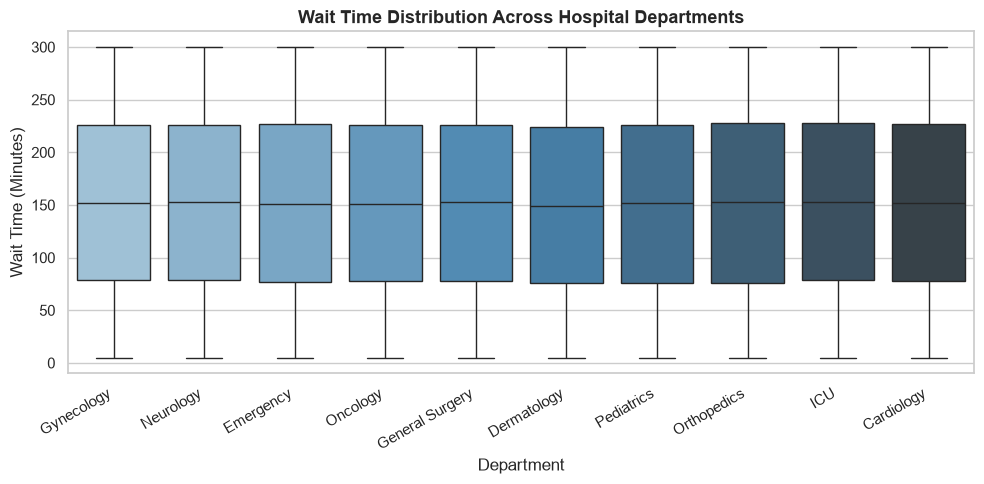

In [26]:
sns.set_theme(style="whitegrid")

# boxplot of wait times by department
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x="department", y="wait_time_mins", palette="Blues_d", hue="department", legend=False)
plt.title("Wait Time Distribution Across Hospital Departments", fontsize=13, fontweight="bold")
plt.xlabel("Department")
plt.ylabel("Wait Time (Minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()



### 14. EDA Visualization 2: Average Length of Stay by Triage Severity
The average inpatient bed stay duration across triage severity tiers to highlight how critical cases lead to long-term bed occupancy.


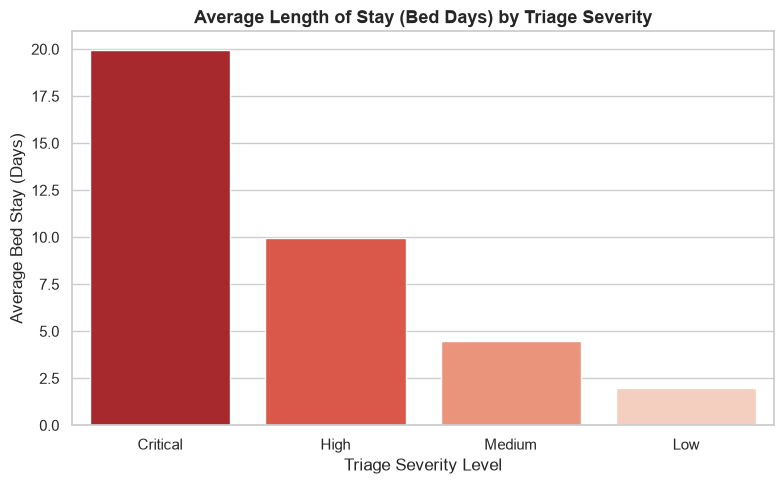

In [27]:
sev_plot = severity_table.reset_index()

# create bar chart of average length of stay by severity
plt.figure(figsize=(8, 5))
sns.barplot(data=sev_plot, x="severity", y="avg_los", palette="Reds_r", hue="severity", legend=False)
plt.title("Average Length of Stay (Bed Days) by Triage Severity", fontsize=13, fontweight="bold")
plt.xlabel("Triage Severity Level")
plt.ylabel("Average Bed Stay (Days)")
plt.tight_layout()

### 15. EDA Visualization 3: Inpatient Length of Stay Distribution
Plot of a histogram of inpatient bed stay duration across all patients to inspect overall bed turnover and skewness.


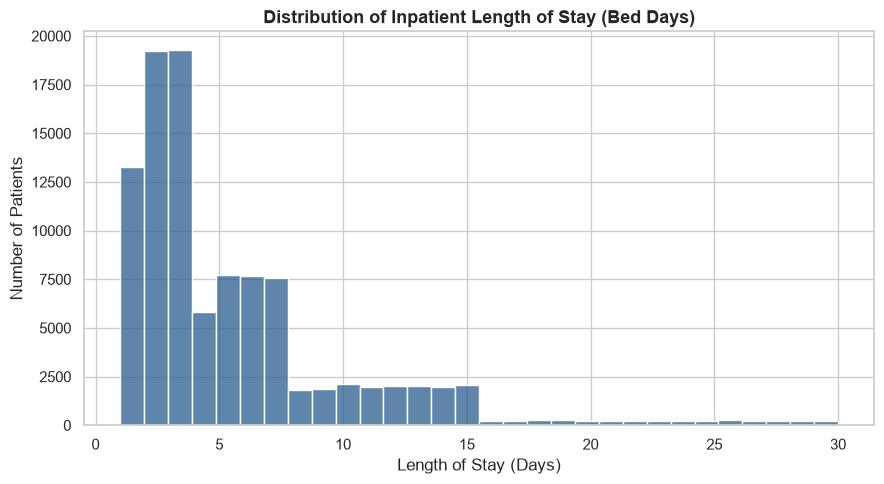

In [29]:
# histogram of inpatient bed stay days
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="bed_stay_days", bins=30, color="#2b5c8f")
plt.title("Distribution of Inpatient Length of Stay (Bed Days)", fontsize=13, fontweight="bold")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Number of Patients")
plt.tight_layout()

### Takeaways for Decision Modeling
* **Uniform static staffing:** every department receives an identical allocation of **500 doctors** (~20 patients per doctor) despite wide differences in clinical acuity, driving average wait times above **150 minutes** across all units.
* **Triage bottleneck:** **Critical** and **High** severity patients wait just as long (~151–152 minutes) as **Low** severity patients, while **80.88%** of all arrivals experience critical delays (>60 minutes).
* **Bed occupancy concentration:** while most admissions discharge within 1–7 days, **Critical** cases average **19.94 bed days**, creating long-term ward congestion that requires targeted bed reallocation and fast-track triage staffing.
